## FRED 기반 미국 금리·물가·경기침체 분석 및 머신러닝 예측

**목표**
1. FRED에서 미국 주요 거시경제 지표 수집
2. 월별 데이터 정리 및 파생변수 생성
3. 10년물 금리와 CPI 상관관계·변화율 분석
4. 장단기 금리차, Sahm Rule, NBER 경기침체 신호 탐지
5. 향후 6개월 경기침체 여부를 머신러닝으로 분류
6. 결과 CSV 저장 및 시각화

**어떤 데이터 사용**
* 7개의 경제지표 사용

| FRED 코드    | 지표              | 이 분석에서의 역할               |
| ---------- | --------------- | ------------------------ |
| `DGS10`    | 미국 10년물 국채금리    | 장기금리 수준과 변화 확인           |
| `DGS2`     | 미국 2년물 국채금리     | 장단기 금리차 계산               |
| `CPIAUCSL` | 소비자물가지수         | 물가상승률 계산                 |
| `FEDFUNDS` | 연방기금금리          | 통화정책 관련 금리 환경 파악         |
| `UNRATE`   | 실업률             | 노동시장 악화 및 Sahm Rule 계산   |
| `PAYEMS`   | 비농업 고용자 수       | 고용 증가·감소 확인              |
| `USREC`    | NBER 기준 경기침체 지표 | 과거 침체 구간 표시 및 머신러닝 정답 생성 |  마크다운으로

* 주의사항
    * 국채금리는 일별, 다른 지표는 월별 : 모든 데이터를 월 단위로 맞춤, 날짜 인덱스는 월초로 통일(이 날짜에 모든 지표가 있는건 아님)

** 주요 경제 분석은?**
1. 10년물 금리와 물가의 관계
2. 금리가 얼마나 변했는가?
3. 장단기 금리차와 금리 역전
4. Sahm Rule과 실제 경기침체 구간\

**머신러닝으로 예측하는 것은?**
* 예측 기준월 다음 달부터 6개월 뒤까지, 경기침체 상태인 달이 한 번이라도 있는가?

**학습 알고리즘**
1. 로지스틱 회귀
2. 랜덤 포레스트

**성능 평가** 
1. 정밀도, 2.재현율, 3. 혼동행렬, 4. ROC-AUC, 5. AP

**산출물(file 단위)** 
1. us_macro_monthly.csv : 월별 통합 데이터와 파생변수
2. correlation_matrix.csv : 지표 간 상관계수
3. model_evaluation.csv : 모델별 평가 점수
4. feature_importance.csv : 랜덤 포레스트 변수 중요도

## 0. 환경 설정 및 라이브러리 설치

In [318]:
# !pip install -q fredapi

In [319]:
# 기본 도구 라이브러리 
import os
import warnings
from pathlib import Path  # 파일 폴더와 경로를 다룸

# 데이터 분석 및 시각화 도구 라이브러리
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 데이터 수집 도구 라이브러리
from fredapi import Fred

# 머신러닝 전처리와 모델 도구 라이브러리
from sklearn.pipeline import Pipeline # 전처리 모델 학습 단계의 흐름을 연결
from sklearn.impute import SimpleImputer   # 결측치를 평균,중앙값 등으로 채움 
from sklearn.preprocessing import StandardScaler  # 평균이 0, 표준편차가 1이 되도록 변환
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# 모델 평가 도구 라이브러리
from sklearn.metrics import (
    classification_report,      # 정밀도, 재현율, F1점수 등을 요약
    confusion_matrix,           # 실제 정답과 예측 결과를 비교해 맞힌 경우와 틀린 경우를 집계
    roc_auc_score,              # 양성과 음성을 구분
    average_precision_score,    # 정밀도와 재현율을 바탕으로 평균 정밀도(AP)를 계산
    RocCurveDisplay,            # ROC 곡선을 그림
    PrecisionRecallDisplay      # 정밀도-재현율 곡선을 그림
)

# 경기침체처럼 발생 빈도가 낮은 사건을 예측할 경우는 정확도 뿐만이 아니라 정밀도, 재현율, F1점수등을 같이 보는것이 중요

In [320]:
# 경고 및 표 출력방식
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 50)  # 최대 50개의 열을 표시
pd.set_option("display.width", 160)       # 표 넓이의 기준을 160으로 설정

# 그래프 기본 설정 
plt.rcParams["figure.figsize"] = (12, 5)  # 가로12 인치, 세로 5인치
plt.rcParams["axes.grid"] = True          # 격자 그래프

RANDOM_STATE = 42           # seed값
START_DATE = "1990-01-01"   # 데이터를 조회할 시작 날짜

# 저장 폴더 만들기 
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

## 1. FRED API 연결
1. [FRED API Key 신청](https://fred.stlouisfed.org/docs/api/api_key.html)
2. 운영체제 환경변수 `FRED_API_KEY`에 발급받은 키 저장

* 키 코드를 직접 입력하거나 GitHub에 업로드 하지 말기 

In [321]:
import platform
from dotenv import load_dotenv
from matplotlib import font_manager

load_dotenv()

FRED_KEY = os.getenv("FRED_API_KEY")

for name, key in {"FRED": FRED_KEY}.items():
    print(f"{name:11s}", "OK" if key else "없음 (해당 기능 건너뜀)")

font = {"Windows": "Malgun Gothic", "Darwin": "AppleGothic", "Linux": "NanumGothic"}.get(platform.system())
if font and any(f.name == font for f in font_manager.fontManager.ttflist):
    plt.rcParams["font.family"] = font
plt.rcParams["axes.unicode_minus"] = False

FRED        OK


## 2. FRED 데이터 수집
| 코드 | 지표 | 빈도·용도 |
|---|---|---|
| DGS10 | 미국 10년물 국채금리 | 일별 |
| DGS2 | 미국 2년물 국채금리 | 일별 |
| CPIAUCSL | 소비자물가지수 | 월별 |
| FEDFUNDS | 연방기금금리 | 월별 |
| UNRATE | 실업률 | 월별 |
| PAYEMS | 비농업 고용자 수 | 월별 |
| USREC | NBER 경기침체 지표 | 월별 |


In [322]:
# 환경변수에서 API 키 읽기
FRED_KEY = os.getenv("FRED_API_KEY")

if not FRED_KEY:
    raise ValueError(
        "FRED_API_KEY 환경변수가 없습니다. "
        "API 키를 환경변수로 설정한 뒤 다시 실행하세요."
    )

fred = Fred(api_key=FRED_KEY)
print("FRED API 연결 객체 생성 완료")

FRED API 연결 객체 생성 완료


In [323]:
SERIES = {
    "DGS10": "미국 10년물 국채금리",
    "DGS2": "미국 2년물 국채금리",
    "CPIAUCSL": "미국 소비자물가지수",
    "FEDFUNDS": "미국 연방기금금리",
    "UNRATE": "미국 실업률",
    "PAYEMS": "미국 비농업 고용자 수",
    "USREC": "NBER 경기침체 지표",
}

raw = {}
for series_id, description in SERIES.items():
    print(f"다운로드: {series_id} - {description}")
    raw[series_id] = fred.get_series(
        series_id,
        observation_start=START_DATE
    )

# 일별 금리의 장단기 금리차 계산
    # 경기침체 가능성을 파악하기 위해서 계산
    # 정상적인 금리차 : 장기 금리가 단기 금리보다 높음
    # 금리 역전(-값) :  단기 금리가 장기 금리보다 높음, 경기침체 위함 신호임
    # 금리차 +1.0% : 장기 금리가 단기 금리보다 크게 높아진 상태임
daily_spread = (raw["DGS10"] - raw["DGS2"]).rename("T10Y2Y")

print("수집 완료")
for series_id, series in raw.items():
    print(f"{series_id}: {len(series):,} observations")

다운로드: DGS10 - 미국 10년물 국채금리
다운로드: DGS2 - 미국 2년물 국채금리
다운로드: CPIAUCSL - 미국 소비자물가지수
다운로드: FEDFUNDS - 미국 연방기금금리
다운로드: UNRATE - 미국 실업률
다운로드: PAYEMS - 미국 비농업 고용자 수
다운로드: USREC - NBER 경기침체 지표
수집 완료
DGS10: 9,616 observations
DGS2: 9,616 observations
CPIAUCSL: 442 observations
FEDFUNDS: 442 observations
UNRATE: 442 observations
PAYEMS: 442 observations
USREC: 442 observations


In [324]:
raw

{'DGS10': 1990-01-01     NaN
 1990-01-02    7.94
 1990-01-03    7.99
 1990-01-04    7.98
 1990-01-05    7.99
               ... 
 2026-11-03    4.95
 2026-11-04    4.90
 2026-11-05    4.84
 2026-11-06    4.86
 2026-11-09    4.88
 Length: 9616, dtype: float64,
 'DGS2': 1990-01-01     NaN
 1990-01-02    7.87
 1990-01-03    7.94
 1990-01-04    7.92
 1990-01-05    7.90
               ... 
 2026-11-03    4.61
 2026-11-04    4.58
 2026-11-05    4.46
 2026-11-06    4.51
 2026-11-09    4.56
 Length: 9616, dtype: float64,
 'CPIAUCSL': 1990-01-01    127.500
 1990-02-01    128.000
 1990-03-01    128.600
 1990-04-01    128.900
 1990-05-01    129.100
                ...   
 2026-06-01    332.568
 2026-07-01    332.813
 2026-08-01    334.131
 2026-09-01    336.298
 2026-10-01    337.476
 Length: 442, dtype: float64,
 'FEDFUNDS': 1990-01-01    8.23
 1990-02-01    8.24
 1990-03-01    8.28
 1990-04-01    8.26
 1990-05-01    8.18
               ... 
 2026-06-01    3.63
 2026-07-01    3.63
 2026-08-01   

## 3. 월별 데이터 통합 및 전처리
* 7개 미국 경제지표를 월별 데이터로 통일하고, 금융·경제 분석에 필요한 파생변수를 추가, Sahm Rule과 12개월 이동 상관관계를 계산

In [325]:
# 1. 일별 금리와 월별 경제지표를 하나의 월별 데이터프레임으로 통합 : 월별 인덱스는 월초(MS)로 통일

# 금리 데이터: 월평균
# resample("MS") : 월초별 데이터로 그룹화
monthly = pd.concat(
    [
        raw["DGS10"].resample("MS").mean().rename("US10Y"),
        raw["DGS2"].resample("MS").mean().rename("US2Y"),
        daily_spread.resample("MS").mean().rename("T10Y2Y"),
        raw["CPIAUCSL"].resample("MS").last().rename("CPI"),  # last인 이유 : 월의 마지막 관측값, 월별 지표
        raw["FEDFUNDS"].resample("MS").last().rename("FEDFUNDS"),
        raw["UNRATE"].resample("MS").last().rename("UNRATE"),
        raw["PAYEMS"].resample("MS").last().rename("PAYEMS"),
        raw["USREC"].resample("MS").max().rename("USREC"),
    ],
    axis=1  # 열 방향으로 붙임
).sort_index()


# 2. 금융·경제 분석에 필요한 파생변수를 추가

# 결과가 3% : 1년 전보다 물가가 3% 상승
# 연간 인플레이션 추세
monthly["CPI_YoY"] = monthly["CPI"].pct_change(12) * 100   # 전년 동월 대비 물가 상승률(YoY)

# 결과가 0.4% : 전월보다 물가가 약 0.4% 상승
# 단기 물가 변화
monthly["CPI_MoM"] = monthly["CPI"].pct_change() * 100     # 전월 대비 물가 상승률(MoM)

# 3개월 전 대비
# 중단기 물가 추세
monthly["CPI_3M"] = monthly["CPI"].pct_change(periods=3) * 100  # 3개월전 대비 물가 상승률(3M)

# 미국 10년물 국채금리(US10Y)의 변화량과 변화율을 계산
monthly["US10Y_Change"] = monthly["US10Y"].diff()   # 전월 대비 금리 변화, 단기 금리 상승·하락 확인
monthly["US10Y_3M_Change"] = monthly["US10Y"].diff(3)  # 3개월전 대비 변화폭, 3개월간 중기 금리 추세 확인
monthly["US10Y_PctChange"] = monthly["US10Y"].pct_change() * 100 # 전월 대비 변화율

# 미국 장단기 금리차를 이용해 금리 역전(Yield Inversion) 여부를 판단
monthly["Yield_Spread"] = monthly["T10Y2Y"]  # T10Y2Y: 미국 10년물 금리 - 2년물 금리 -> 장단기 금리차
# 미국 장단기 금리차가 마이너스인지 확인하여 금리 역전 여부를 0과 1로 표시 : 머신러닝에서 사용할 수 있는 변수를 만드는 과정
monthly["Yield_Inversion"] = (monthly["Yield_Spread"] < 0).astype("Int64")

# PAYEMS : 비농업 고용자 수, 단위 천명(159,000-> 약 1억 5900만명), 계절조정된 데이터
    # 12월 : 연말 쇼핑·배송 인력 증가, 1월 : 연말 임시직 계약 종료로 고용 감소, 5~6월 : 여름철 관광·서비스업 채용 증가, 9월 : 여름철 임시직 감소
# 미국의 일자리 증가 또는 감소 규모를 파악
monthly["PAYEMS_Change"] = monthly["PAYEMS"].diff()  # 전월 대비 고용자 수 변화
monthly["PAYEMS_YoY"] = monthly["PAYEMS"].pct_change(12) * 100  # 전년 동월 대비 고용자 수 변화율

# 3. Sahm Rule과 12개월 이동 상관관계를 계산
# 미국 실업률의 상승 추세등을 이용해 경기 침체 가능성을 조기에 파악하는 지표
# 최근 3개월 평균 실업률이 과거 12개월 동안의 최저 3개월 평균보다 0.5%p 이상 상승했는가?

# 최근 3개월 평균 실업률
# rolling(3) : 최근 3개월 행을 묶어서 계산, min_periods=3 : 최소 3개월 데이터가 있어야 계산, .mean() : 3개월 평균 계산 
monthly["UNRATE_3M"] = monthly["UNRATE"].rolling(3, min_periods=3).mean()
# 과거 12개월 중 최저 3개월 평균
monthly["UNRATE_LOW_12M"] = monthly["UNRATE_3M"].rolling(12, min_periods=12).min()

# 현재 3개월 평균 실업률에서 최근 12개월 중 최저 3개월 평균 실업률
monthly["Sahm_Rule"] = monthly["UNRATE_3M"] - monthly["UNRATE_LOW_12M"]
# 경기침체 신호 판단 - Sahm Rule이 0.50%p 이상이면 경기침체 신호를 1로 표시(1 = Sahm Rule 발동, 0 = 미발동)
monthly["Sahm_Signal"] = (monthly["Sahm_Rule"] >= 0.50).astype("Int64")

# 12개월 이동 상관관계, 최근 12개월 동안 미국 10년물 국채 금리(US10Y)와 미국 소비자물가지수 상승률(CPI_YoY) 사이의 상관관계 분석
monthly["Rolling_Corr_12M"] = (
    monthly["US10Y"].rolling(12).corr(monthly["CPI_YoY"])
)

print("월별 데이터 크기:", monthly.shape)
display(monthly.tail(10))

월별 데이터 크기: (443, 23)


,US10Y,US2Y,T10Y2Y,CPI,FEDFUNDS,UNRATE,PAYEMS,USREC,CPI_YoY,CPI_MoM,CPI_3M,US10Y_Change,US10Y_3M_Change,US10Y_PctChange,Yield_Spread,Yield_Inversion,PAYEMS_Change,PAYEMS_YoY,UNRATE_3M,UNRATE_LOW_12M,Sahm_Rule,Sahm_Signal,Rolling_Corr_12M
2026-02-01,4.125789,3.471579,0.654211,327.460,3.64,4.4,158436.0,0.0,2.434004,0.267003,0.737396,-0.087711,0.031901,-2.081655,0.654211,0,-156.0,0.079591,4.366667,NaN,NaN,0,-0.270100
2026-03-01,4.245909,3.714545,0.531364,330.293,3.64,4.3,158650.0,0.0,3.285958,0.865144,1.307238,0.120120,0.102727,2.911434,0.531364,0,214.0,0.172374,4.333333,NaN,NaN,0,-0.158554
2026-04-01,4.319091,3.799091,0.520000,332.407,3.64,4.3,158798.0,0.0,3.779246,0.640038,1.781756,0.073182,0.105591,1.723584,0.520000,0,148.0,0.197495,4.333333,NaN,NaN,0,0.087924
2026-05-01,4.484000,3.995000,0.489000,333.979,3.63,4.3,158861.0,0.0,4.166615,0.472914,1.990777,0.164909,0.358211,3.818144,0.489000,0,63.0,0.229025,4.300000,NaN,NaN,0,0.581707
2026-06-01,4.470476,4.112857,0.357619,332.568,3.63,4.2,158892.0,0.0,3.463531,-0.422482,0.688782,-0.013524,0.224567,-0.301601,0.357619,0,31.0,0.261235,4.266667,NaN,NaN,0,0.703482
2026-07-01,4.599545,4.222727,0.376818,332.813,3.63,4.1,158882.0,0.0,3.303856,0.073669,0.122139,0.129069,0.280455,2.887148,0.376818,0,-10.0,0.214454,4.200000,NaN,NaN,0,0.715426
2026-08-01,4.684286,4.216190,0.468095,334.131,3.63,4.1,159068.0,0.0,3.353016,0.396018,0.045512,0.084740,0.200286,1.842362,0.468095,0,186.0,0.376092,4.133333,NaN,NaN,0,0.663138
2026-09-01,4.989048,4.651429,0.337619,336.298,3.75,4.2,159128.0,0.0,3.717251,0.648548,1.121575,0.304762,0.518571,6.506049,0.337619,0,60.0,0.365820,4.133333,NaN,NaN,0,0.674379
2026-10-01,5.130952,4.743333,0.387619,337.476,3.88,4.1,159293.0,0.0,4.080556,0.350285,1.401087,0.141905,0.531407,2.844326,0.387619,0,165.0,0.558684,4.133333,NaN,NaN,0,0.719825
2026-11-01,4.890000,4.551667,0.338333,NaN,NaN,NaN,NaN,NaN,3.818644,0.000000,1.001104,-0.240952,0.205714,-4.696056,0.338333,0,NaN,0.532664,NaN,NaN,NaN,0,0.709728


## 4. 데이터 품질 점검
* 월별 경제지표 데이터의 품질을 점검
* 각 컬럼의 결측치 개수, 결측률, 실제 데이터 시작일과 종료일 확인, 전체 데이터 기간을 출력

In [326]:
quality = pd.DataFrame({
    "missing_count": monthly.isna().sum(),                              # 컬럼별 결측치 개수
    "missing_pct": (monthly.isna().mean() * 100).round(2),              # 컬럼별 결측치 비율(%)
    "first_valid": monthly.apply(lambda s: s.first_valid_index()),      # 첫 번째 유효 데이터 날짜
    "last_valid": monthly.apply(lambda s: s.last_valid_index())         # 마지막 유효 데이터 날짜
})

display(quality)
print("전체 기간:", monthly.index.min(), "~", monthly.index.max())

,missing_count,missing_pct,first_valid,last_valid
US10Y,0,0.00,1990-01-01,2026-11-01
US2Y,0,0.00,1990-01-01,2026-11-01
T10Y2Y,0,0.00,1990-01-01,2026-11-01
CPI,2,0.45,1990-01-01,2026-10-01
FEDFUNDS,1,0.23,1990-01-01,2026-10-01
UNRATE,2,0.45,1990-01-01,2026-10-01
PAYEMS,1,0.23,1990-01-01,2026-10-01
USREC,1,0.23,1990-01-01,2026-10-01
CPI_YoY,12,2.71,1991-01-01,2026-11-01
CPI_MoM,1,0.23,1990-02-01,2026-11-01


전체 기간: 1990-01-01 00:00:00 ~ 2026-11-01 00:00:00


### 4-1. 상관분석 전 피처 점검과 결측 처리

In [327]:

CORR_COLS = ["US10Y", "CPI_YoY", "FEDFUNDS", "UNRATE", "T10Y2Y"]  # 상관분석에 쓸 5개 컬럼
DERIVED_COLS = [                                                  # 파생변수 목록
    "CPI_YoY", "CPI_MoM",                                         # 물가(전년동월대비변화율(%), 전월대비변화율(%)) : 원천 CPI 
    "US10Y_Change", "US10Y_3M_Change", "US10Y_PctChange",         # 금리변화(전월대비변화폭(%p), 3개월전대비변화폭(%p), 전월대비변화율(%)) : 원천 US10Y
    "Yield_Spread", "Yield_Inversion",                            # 장단기 금리차(T10Y2Y와 같은값, 금리차가0보다작으면1/결측은NA) : 원천 T10Y2Y
    "PAYEMS_Change", "PAYEMS_YoY",                                # 고용(월간증감(천명), 전년동월대비변화율(%) : 원천 PAYEMS
    "UNRATE_3M", "UNRATE_LOW_12M", "Sahm_Rule", "Sahm_Signal",    # 침체신호(Sahm Rule)(실업률3개월평균과그12개월최저, 두값의차이, 0.5 이상이면1/결측은NA) : 원천 UNRATE
    "Rolling_Corr_12M", "Imputed",                                # 상관·관리(US10Y와CPI_YoY의12개월롤링상관, 보간한달이면1 (0/1 표시열)) : 원천 US10Y, CPI_YoY
]
# 원자료별 보간 방식 
FILL_PLAN = {
    "US10Y": "time",      # 일별 금리의 월평균: 연속적으로 변함 → 선형(시간) 보간
    "US2Y": "time",       # 일별 금리의 월평균: 연속적으로 변함 → 선형(시간) 보간
    "T10Y2Y": "time",     # 장단기 금리차의 월평균: 연속적으로 변함 → 선형(시간) 보간
    "CPI": "time",        # 물가 지수 수준: 완만하게 증가 → 선형(시간) 보간
    "UNRATE": "time",     # 실업률: 월간 변화가 작음 → 선형(시간) 보간
    "PAYEMS": "time",     # 고용자 수 수준: 완만하게 증가 → 선형(시간) 보간
    "FEDFUNDS": "ffill",  # 정책금리: 계단식 변화 → 직전 값 유지
    "USREC": None,        # NBER 침체 여부(0/1): 보간하면 0.5 같은 값이 생기므로 그대로 둠
}

MAX_GAP = 1               # 이 개월 수 이하의 '중간' 연속 결측만 보간, 연손 결측이 1개월 이하일 때만 채움

# 중복·정렬·월 행 누락
# 시간 인덱스가 올바르게 구성되어 있는지 점검하고, 시간 순서대로 정렬 : 날짜가 중복이 되어있거나, 잘못된 시간 순서가 있는지 확인(분석에 영향을 미칠수 있음)
print("■ 구조 점검")
n_dup = int(monthly.index.duplicated().sum()) 
if n_dup:
    raise ValueError(f"중복 인덱스 {n_dup}개: 먼저 정리한 뒤 다시 실행하세요.")
monthly = monthly.sort_index()

# monthly 데이터프레임의 날짜 인덱스가 매월 1일(월초) 기준으로 구성되어 있는지 검사
# date_range() : 시작 날짜부터 종료 날짜까지 일정한 간격의 날짜를 생성하는 함수, 
# freq="MS" : 매월 첫 번째 날짜, monthly.index.name : 기존의 인덱스 이름 유지
full_idx = pd.date_range(monthly.index.min(), monthly.index.max(), freq="MS", name=monthly.index.name)
off_grid = monthly.index.difference(full_idx)
if len(off_grid):
    raise ValueError(f"월초(MS)가 아닌 인덱스가 있습니다: {list(off_grid[:5])}")

# 월별 데이터에서 통째로 빠진 달이 있는지 확인하고, 빠진 달을 결측값(NaN) 행으로 추가
missing_rows = full_idx.difference(monthly.index)
print(f"  행 수 {len(monthly)}개 | 기간 {full_idx.min():%Y-%m} ~ {full_idx.max():%Y-%m}")
print(f"  누락된 월 행: {[d.strftime('%Y-%m') for d in missing_rows] or '없음'}")
if len(missing_rows):
    # 월 행이 빠져 있으면 pct_change(12)·rolling(12)의 '12개월'이 어긋나므로 빈 행으로 채움
    monthly = monthly.reindex(full_idx)

# 전체 컬럼에서 파생변수를 제외하고 남은 컬럼을 숫자형과 비숫자형으로 나누는 작업
RAW_COLS = [c for c in monthly.columns if c not in DERIVED_COLS]
# 원자료 중 숫자형 컬럼 찾기
NUM_RAW = [c for c in RAW_COLS if pd.api.types.is_numeric_dtype(monthly[c])]
# 원자료 중 비숫자형 컬럼 찾기
NON_NUM_RAW = [c for c in RAW_COLS if c not in NUM_RAW]
# 원자료 개수와 이름 출력
print(f"  원자료 {len(RAW_COLS)}개: {RAW_COLS}")
if NON_NUM_RAW:
    print(f"  ※ 숫자형이 아니어서 보간하지 않는 컬럼: {NON_NUM_RAW}")



■ 구조 점검
  행 수 443개 | 기간 1990-01 ~ 2026-11
  누락된 월 행: 없음
  원자료 9개: ['US10Y', 'US2Y', 'T10Y2Y', 'CPI', 'FEDFUNDS', 'UNRATE', 'PAYEMS', 'USREC', 'CPI_3M']


In [328]:
display(NUM_RAW)
display(NON_NUM_RAW)

['US10Y',
 'US2Y',
 'T10Y2Y',
 'CPI',
 'FEDFUNDS',
 'UNRATE',
 'PAYEMS',
 'USREC',
 'CPI_3M']

[]

In [329]:
monthly_before_clean = monthly.copy() 

# 결측값을 채우기 전에 데이터 상태를 점검하는 것
# 결측에 대한 보간 방법
    # 시작/끝 결측은 한쪽값이 없어 추정 근거가 부족
        # (시작결측 : 역방향 채우기, 끝 결측 : 그값 그대로 표시할수 있도록 특정 숫자로 채우기(0), 마지막 나오는 관측 값의 시점까지만 측정)
    # 중간 결측은 앞뒤 값으로 추정할 수 있음
        # 짧은결측 : 앞뒤 정상값이 있고 연속 결측이 1개월 이하인 중간 구간만 지정된 방법으로 채움, 2개월 이상이다라고 하면 그대로 결측값 두기
def gap_info(s):  # 하나의 필드가 Input
    """시작 결측 / 중간 결측 / 끝 결측 개수와 가장 긴 중간 결측 길이."""
    first, last = s.first_valid_index(), s.last_valid_index()
    if first is None:
        return {"시작 결측": len(s), "중간 결측": 0, "최장 중간 결측": 0, "끝 결측": 0,
                "첫 유효월": pd.NaT, "마지막 유효월": pd.NaT}
    inner_na = s.loc[first:last].isna()
    runs = inner_na.groupby((~inner_na).cumsum()).sum()
    return {
        "시작 결측": int((s.index < first).sum()),   # 첫 정상값이 나오기 이전에 빠진 값 
        "중간 결측": int(inner_na.sum()),            # 시작 결측이 아닌, 첫번째 나오는 정상값과 마지막 정상값 사이에 빠진 값의 총 개수
        "최장 중간 결측": int(runs.max()) if len(runs) else 0,    # 중간 결측중 끊기지 않고 이어진 가장 긴 구간 
        "끝 결측": int((s.index > last).sum()),    # 마지막 정상 값이 나온 이후에 빠진 값 
        "첫 유효월": first,       # 첫 번째 정상 값의 날짜
        "마지막 유효월": last,     # 마지막 정상 값의 날짜 
    }
    # return 값에서 정상값이라고 하는 것은 단순히 NaN값을 의미

summary = pd.DataFrame({c: gap_info(monthly[c]) for c in monthly.columns}).T
summary.insert(0, "dtype", monthly.dtypes.astype(str))
summary.insert(1, "결측수", monthly.isna().sum())
summary.insert(2, "결측률(%)", (monthly.isna().mean() * 100).round(1))
print("\n■ 전체 컬럼 결측 현황 (파생변수의 시작 결측은 12개월 윈도 등 계산상 정상)")
display(summary)

''' 
1. 원자료   
US10Y, US2Y, T10Y2Y : 결측값 없이 2026년 11월까지 값이 있음
CPI, UNRATE : 중간에 1개월 결측, 끝에 1개월 결측
FEDFUNDS, PAYEMS, USREC : 중간 결측은 없고, 끝에 1개월 결측

2. 파생변수의 시작 결측:계산에 필요한 과거 값이 없음
CPI_YoY, PAYEMS_YoY : 시작결측 12개월 / 이유는 12개월 전 값이 필요함
CPI_MoM, US10Y_Change, US10Y_PctChange, PAYEMS_Change : 시작결측 1개월 / 직전 달 값이 필요
US10Y_3M_Change : 시작결측 3개월 / 3개월 전 값이 필요
  - 현재 달 금리 - 3개월 전 금리 : 현재달이 1990년 1월 이라고 하면 3개월전 비교 날짜 1989년 10월(이 데이터가 없음)
UNRATE_3M : 시작결측 2개월 / 3개월치 값이 모여야 계산 가능
UNRATE_LOW_12M, Sahm_Rule : 시작결측 13 개월 / 3개월 평균을 만든 뒤, 그 평균이 12개 모여야 함
Rolling_Corr_12M : 시작결측 23개월 / CPI 전년 대비 변화율이 만들어진 뒤, 12개월치 쌍이 필요

'''


■ 전체 컬럼 결측 현황 (파생변수의 시작 결측은 12개월 윈도 등 계산상 정상)


,dtype,결측수,결측률(%),시작 결측,중간 결측,최장 중간 결측,끝 결측,첫 유효월,마지막 유효월
US10Y,float64,0,0.0,0,0,0,0,1990-01-01 00:00:00,2026-11-01 00:00:00
US2Y,float64,0,0.0,0,0,0,0,1990-01-01 00:00:00,2026-11-01 00:00:00
T10Y2Y,float64,0,0.0,0,0,0,0,1990-01-01 00:00:00,2026-11-01 00:00:00
CPI,float64,2,0.5,0,1,1,1,1990-01-01 00:00:00,2026-10-01 00:00:00
FEDFUNDS,float64,1,0.2,0,0,0,1,1990-01-01 00:00:00,2026-10-01 00:00:00
UNRATE,float64,2,0.5,0,1,1,1,1990-01-01 00:00:00,2026-10-01 00:00:00
PAYEMS,float64,1,0.2,0,0,0,1,1990-01-01 00:00:00,2026-10-01 00:00:00
USREC,float64,1,0.2,0,0,0,1,1990-01-01 00:00:00,2026-10-01 00:00:00
CPI_YoY,float64,12,2.7,12,0,0,0,1991-01-01 00:00:00,2026-11-01 00:00:00
CPI_MoM,float64,1,0.2,1,0,0,0,1990-02-01 00:00:00,2026-11-01 00:00:00


' \n1. 원자료   \nUS10Y, US2Y, T10Y2Y : 결측값 없이 2026년 11월까지 값이 있음\nCPI, UNRATE : 중간에 1개월 결측, 끝에 1개월 결측\nFEDFUNDS, PAYEMS, USREC : 중간 결측은 없고, 끝에 1개월 결측\n\n2. 파생변수의 시작 결측:계산에 필요한 과거 값이 없음\nCPI_YoY, PAYEMS_YoY : 시작결측 12개월 / 이유는 12개월 전 값이 필요함\nCPI_MoM, US10Y_Change, US10Y_PctChange, PAYEMS_Change : 시작결측 1개월 / 직전 달 값이 필요\nUS10Y_3M_Change : 시작결측 3개월 / 3개월 전 값이 필요\n  - 현재 달 금리 - 3개월 전 금리 : 현재달이 1990년 1월 이라고 하면 3개월전 비교 날짜 1989년 10월(이 데이터가 없음)\nUNRATE_3M : 시작결측 2개월 / 3개월치 값이 모여야 계산 가능\nUNRATE_LOW_12M, Sahm_Rule : 시작결측 13 개월 / 3개월 평균을 만든 뒤, 그 평균이 12개 모여야 함\nRolling_Corr_12M : 시작결측 23개월 / CPI 전년 대비 변화율이 만들어진 뒤, 12개월치 쌍이 필요\n\n'

In [330]:
# 원자료 컬럼별로 "어느 달의 값이 빠졌는지" 를 출력 : 결측 날짜 목록
# 중간 결측과 끝 결측을 구분하기 위함 : 경제지표의 끝 결측은 아직 발표되지 않은 값일 수도 있기 때문에 생성이 될 가능성을 위해 남겨두기 위함
print("원자료별 결측 월")
for c in RAW_COLS:
    s = monthly[c]
    # 첫 정상 값과 마지막 정상 값의 날짜 찾기
    first, last = s.first_valid_index(), s.last_valid_index()  
    if first is None:  # 모든 값이 결측인 컬럼
        print(f"  {c:12s} 전부 결측")
        continue

    #  중간에 빠진 달의 목록 만들기
    inner = s.loc[first:last]
    inner_gaps = [d.strftime("%Y-%m") for d in inner[inner.isna()].index]  # 결측에 대한 날짜만 추출
    tail_gaps = [d.strftime("%Y-%m") for d in s.loc[s.index > last].index]  # 마지막 정상 값의 날짜보다 뒤에 있는 행을 찾음 : 끝 결측을 찾기 위함 
    print(f"  {c:12s} 중간 결측: {inner_gaps or '없음'} | 끝 결측: {tail_gaps or '없음'}")

원자료별 결측 월
  US10Y        중간 결측: 없음 | 끝 결측: 없음
  US2Y         중간 결측: 없음 | 끝 결측: 없음
  T10Y2Y       중간 결측: 없음 | 끝 결측: 없음
  CPI          중간 결측: ['2025-10'] | 끝 결측: ['2026-11']
  FEDFUNDS     중간 결측: 없음 | 끝 결측: ['2026-11']
  UNRATE       중간 결측: ['2025-10'] | 끝 결측: ['2026-11']
  PAYEMS       중간 결측: 없음 | 끝 결측: ['2026-11']
  USREC        중간 결측: 없음 | 끝 결측: ['2026-11']
  CPI_3M       중간 결측: 없음 | 끝 결측: 없음


In [331]:
# 숫자형 컬럼들의 값 분포를 요약하고, 계산 과정에서 무한대(inf)가 생겼는지 확인

# 숫자형 컬럼만 선택
num_all = monthly.select_dtypes("number").astype("float64")
print("\n■ 숫자형 전체 컬럼 요약 통계")
# 요약 통계 출력
display(num_all.describe().T.round(2))
# 무한대가 있는 컬럼 찾기 : np.isinf(num_all)->inf, -inf 면 True 
inf_cols = {c: int(n) for c, n in np.isinf(num_all).sum().items() if n}
print(f"  무한대(inf) 값이 있는 컬럼: {inf_cols or '없음'}")


■ 숫자형 전체 컬럼 요약 통계


,count,mean,std,min,25%,50%,75%,max
US10Y,443.0,4.26,1.92,0.62,2.66,4.20,5.67,8.89
US2Y,443.0,3.26,2.24,0.12,0.97,3.52,4.96,8.72
T10Y2Y,443.0,1.00,0.91,-0.93,0.25,0.82,1.76,2.83
CPI,441.0,212.77,54.11,127.50,164.80,212.69,244.24,337.48
FEDFUNDS,442.0,2.90,2.32,0.05,0.34,2.97,5.22,8.29
UNRATE,441.0,5.64,1.74,3.40,4.30,5.30,6.50,14.80
PAYEMS,442.0,134416.21,14018.10,108253.00,128324.25,133413.50,144570.25,159293.00
USREC,442.0,0.08,0.27,0.00,0.00,0.00,0.00,1.00
CPI_YoY,431.0,2.64,1.53,-1.96,1.73,2.60,3.20,8.98
CPI_MoM,442.0,0.22,0.27,-1.77,0.10,0.22,0.34,1.38


  무한대(inf) 값이 있는 컬럼: 없음


In [332]:
# 완료된 달의 데이터만 남기기 

# 실행시점의 날짜 만들기(이번달의 시작 날짜 만들기)
this_month = pd.Timestamp.today().to_period("M").to_timestamp()
# 제외할 월의 날짜를 저장, 이번 달 1일 이상인 날짜를 추출
partial = monthly.index[monthly.index >= this_month]
# 제외할 월의 날짜를 저장, 이번 달 1일 이전인 날짜를 추출
monthly = monthly.loc[monthly.index < this_month].copy()
print(f"\n■ 삭제한 미완성 월: {[d.strftime('%Y-%m') for d in partial] or '없음'}")


■ 삭제한 미완성 월: ['2026-11']


In [333]:
# 짧은 중간 결측만 채움(원자료 전체)

# 시작 결측 : 그대로 둠, 중간짧은 결측 : 지정방식대로 보간, 중간 2개월 이상 연속빠짐/끝부분 결측 : 그대로 둠
# method="time" : 기본값은 시간 기준 보간 
# max_gap : 채울 수 있는 연속 결측 길이의 최댓값
def fill_short_gaps(s, method="time", max_gap=1):
    # 결측인 위치 찾기
    isna = s.isna()
    # 각 결측 위치가 몇 개짜리 연속 결측 구간에 속하는지 확인
    # ex) 값: 100 → NaN → 104 → NaN → NaN → 110 : 첫 번째 NaN(1), 두 번째 NaN(2), 세 번째 NaN(2)
    # (~isna) : 결측이면 False, .cumsum() : 누적합(새로운 값이 나올경우 +1씩 증가:값의 종류별로), 그룹 번호 만들기
        #  True  False / True  False  False  False / True : 0, 1, 2 그룹핑
    run_len = isna.groupby((~isna).cumsum()).transform("sum")   # 결측 구간 길이
    #  여기
    inside = s.ffill().notna() & s.bfill().notna()              # 앞뒤에 관측값이 모두 있는 위치
    target = isna & inside & (run_len <= max_gap)
    filled = s.ffill() if method == "ffill" else s.interpolate(method=method)
    return s.where(~target, filled)  # target이 True인 것만 보간을 함(filled)

In [334]:
imputed_log = []
for col in NUM_RAW:
    method = FILL_PLAN.get(col)          # 계획에 없거나 None이면 채우지 않음
    if method is None:
        continue
    before = monthly[col]
    after = fill_short_gaps(before, method, MAX_GAP)
    for d in after.index[before.isna() & after.notna()]:
        imputed_log.append({"month": d.strftime("%Y-%m"), "column": col,
                            "method": method, "value": round(float(after[d]), 3)})
    monthly[col] = after

In [335]:
# 어떤 열을 보간하고, 보간하지 않았는지를 기록으로 보고, 점검부분
# 열을 새로 추가하거나 처리 방침을 잊어버릴경우에 대한 실수를 방지하기 위한 안전장치 

# 보간 계획에서 빠진 열 찾기, NUM_RAW는 숫자형 원자료 열 목록, FILL_PLAN은 보간 방식을 정해 둔 열
not_planned = [c for c in NUM_RAW if c not in FILL_PLAN]
if not_planned:
    print(f"\n※ FILL_PLAN에 없어 보간하지 않은 숫자형 원자료: {not_planned}")

# 보간된 달에 표시붙이기 : 결과적으로 Imputed 필드가 생김, 보간된달은 1, 아니면 0으로 정리, 추정치를 추적하기 위함임 *****
# [r["month"] for r in imputed_log] : ["2025-10"]
# monthly.index.strftime("%Y-%m") : "2025-10" 인덱스로 변환 
# isin : 각 달이 보간된 달 목록에 있으면 True, 아니면 False, .astype(int) : 1/0으로 처리
monthly["Imputed"] = monthly.index.strftime("%Y-%m").isin([r["month"] for r in imputed_log]).astype(int)
print("\n■ 보간한 값 (공식 발표값이 아닌 추정치)")
display(pd.DataFrame(imputed_log) if imputed_log else "보간한 값 없음")


※ FILL_PLAN에 없어 보간하지 않은 숫자형 원자료: ['CPI_3M']

■ 보간한 값 (공식 발표값이 아닌 추정치)


,month,column,method,value
0,2025-10,CPI,time,324.647
1,2025-10,UNRATE,time,4.449


In [336]:
# 새로운 파생변수 계산

# 변화율: pct_change
monthly["CPI_YoY"] = monthly["CPI"].pct_change(12, fill_method=None) * 100
monthly["CPI_MoM"] = monthly["CPI"].pct_change(fill_method=None) * 100

# 금리 변화: diff
monthly["US10Y_Change"] = monthly["US10Y"].diff()                                   # %p (퍼센트포인트)
monthly["US10Y_3M_Change"] = monthly["US10Y"].diff(3)                               # %p (퍼센트포인트)
monthly["US10Y_PctChange"] = monthly["US10Y"].pct_change(fill_method=None) * 100    # % (상대 변화율)

# 장단기 금리차와 역전
monthly["Yield_Spread"] = monthly["T10Y2Y"]
monthly["Yield_Inversion"] = (monthly["Yield_Spread"] < 0).astype("Int64").where(monthly["Yield_Spread"].notna())

# 고용
monthly["PAYEMS_Change"] = monthly["PAYEMS"].diff()
monthly["PAYEMS_YoY"] = monthly["PAYEMS"].pct_change(12, fill_method=None) * 100

# Sahm Rule(실업률 급등 신호)

# 최근 3개월 실업률의 평균, 한 달의 튀는 값을 방지하고자 3개월 단위로 봄 
monthly["UNRATE_3M"] = monthly["UNRATE"].rolling(3, min_periods=3).mean()
# rolling(n)은 최근 n개월 창을 한 칸씩 밀면서 계산하는 함수
# 3개월 실업률의 평균 값의 최근 12개월 중 최저값, 직전 1년 바닥값 
monthly["UNRATE_LOW_12M"] = monthly["UNRATE_3M"].rolling(12, min_periods=12).min()
# 현재 평균이 직전 1년 바닥보다 얼마나 올랐는지를 확인
monthly["Sahm_Rule"] = monthly["UNRATE_3M"] - monthly["UNRATE_LOW_12M"]
# 상승폭이 0.5%p 이상이면 1, 실업률이 저점에서 빠르게 오르면 침체 신호로 보는 규칙
monthly["Sahm_Signal"] = (monthly["Sahm_Rule"] >= 0.50).astype("Int64").where(monthly["Sahm_Rule"].notna())

# 12개월 이동 상관

# 최근 12개월 동안 10년물 금리와 CPI 상승률이 얼마나 같이 움직였는지를 매달 계산
monthly["Rolling_Corr_12M"] = monthly["US10Y"].rolling(12).corr(monthly["CPI_YoY"])

In [337]:
# 결과 확인
# 처리 전후로 열마다 결측이 몇 개에서 몇 개로 바뀌었는지 한 표로 비교하는 점검
print("처리 전후 비교 (전체 컬럼 결측 개수, 같은 행 기준)")
before_aligned = monthly_before_clean.reindex(index=monthly.index, columns=monthly.columns)
cmp = pd.DataFrame({
    "before": before_aligned.isna().sum(),
    "after": monthly.isna().sum(),
})
cmp["변화"] = cmp["after"] - cmp["before"]
cmp = cmp.drop(index="Imputed")  
display(cmp)

# 남은 중간 결측 찾기
print("■ 보간 후에도 남은 원자료의 중간 결측 (길이가 MAX_GAP 초과 또는 보간 제외 컬럼)")
left = False
for c in NUM_RAW:
    s = monthly[c]
    first, last = s.first_valid_index(), s.last_valid_index()
    if first is None:
        continue
    inner = s.loc[first:last]
    gaps = [d.strftime("%Y-%m") for d in inner[inner.isna()].index]
    if gaps:
        left = True
        print(f"  {c:12s} {gaps}")
if not left:
    print("  없음")

corr_ready = monthly[CORR_COLS].dropna()
print(f"\n상관분석에 쓰이는 행 수: {len(corr_ready)}개 "
      f"({corr_ready.index.min():%Y-%m} ~ {corr_ready.index.max():%Y-%m})")

처리 전후 비교 (전체 컬럼 결측 개수, 같은 행 기준)


,before,after,변화
US10Y,0,0,0
US2Y,0,0,0
T10Y2Y,0,0,0
CPI,1,0,-1
FEDFUNDS,0,0,0
UNRATE,1,0,-1
PAYEMS,0,0,0
USREC,0,0,0
CPI_YoY,12,12,0
CPI_MoM,1,1,0


■ 보간 후에도 남은 원자료의 중간 결측 (길이가 MAX_GAP 초과 또는 보간 제외 컬럼)
  없음

상관분석에 쓰이는 행 수: 430개 (1991-01 ~ 2026-10)


## 미국 10년물 금리와 CPI 상관관계

전체 기간 상관관계


,US10Y,CPI_YoY,FEDFUNDS,UNRATE,T10Y2Y
US10Y,1.000,0.203,0.799,-0.124,-0.126
CPI_YoY,0.203,1.000,0.281,-0.349,-0.320
FEDFUNDS,0.799,0.281,1.000,-0.482,-0.642
UNRATE,-0.124,-0.349,-0.482,1.000,0.719
T10Y2Y,-0.126,-0.320,-0.642,0.719,1.000


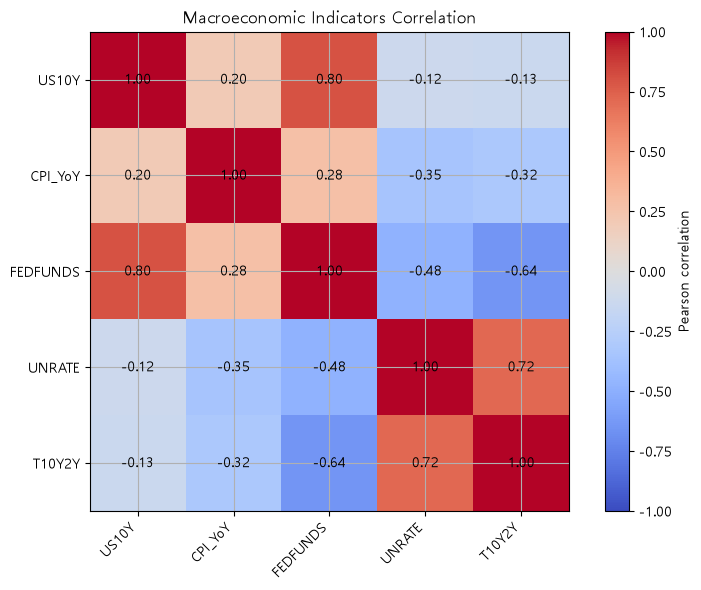

In [338]:
# 미국 거시경제 지표 5개(10년물 국채금리, CPI 상승률, 기준금리, 실업률, 장단기 금리차)
# 피어슨 상관계수를 계산해 5×5 행렬
corr_data = monthly[["US10Y", "CPI_YoY", "FEDFUNDS", "UNRATE", "T10Y2Y"]].dropna()
corr_matrix = corr_data.corr()

print("전체 기간 상관관계")
display(corr_matrix.round(3))

fig, ax = plt.subplots(figsize=(8, 6))
# vmin=-1, vmax=1 색 범위를 고정해서 파란색은 음의상관, 빨간색은 양의상관, 흰색 상관 거의없음
im = ax.imshow(corr_matrix, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.index)))
ax.set_xticklabels(corr_matrix.columns, rotation=45, ha="right")
ax.set_yticklabels(corr_matrix.index)

for i in range(len(corr_matrix.index)):
    for j in range(len(corr_matrix.columns)):
        ax.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center")

fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Macroeconomic Indicators Correlation")
plt.tight_layout()
plt.show()


In [339]:
''' 
## 결과 해석 ##
= US10Y ↔ FEDFUNDS (0.80)
* 미국 10년물 국채금리가 상승하는 시기에 연방기금금리도 상승하는 경향이 강했고, 반대로 하락할 때도 함께 하락하는 경향
* 경기 호황 : US10Y, FEDFUNDS 둘다 상승 경향
* 경기 과열 : US10Y은 인플레이션 우려로 상승 가능, FEDFUNDS 연준 금리 인상
* 경기 둔화 : US10Y은 하락 가능, FEDFUNDS 동결 또는 인하 가능
* 경기 침체 :US10Y은 하락 가능, FEDFUNDS 금리 인하 가능

= UNRATE ↔ T10Y2Y (0.72)
* 두 번째로 강한 양의 상관 관계임, 실업률이 높을 때 장단기 스프레드가 넓었다는 의미
* 경기침체 : 금리 인하로 단기금리가 떨어지면서 스프레드가 확대되는 패턴과 부합
* 경기침체 전에는 장단기 금리가 역전되고, 경기침체가 진행되면서 실업률이 상승하고 단기금리가 하락하면 장단기 금리 차이가 다시 확대될 수 있음

= FEDFUNDS ↔ T10Y2Y (-0.64) 
* 정책금리가 높을수록 스프레드가 좁아지거나 역전되는 경향을 보임
* 연준이 기준금리를 올리는 긴축 국면에서 장단기 금리 역전 현상이 발생할 가능성이 커짐 
* FEDFUNDS   /    T10Y2Y             /   해석
  상승             하락                금리차이축소
  추가상승          추가 하락 가능       금리역전가능
  하락             상승                금리 차이 확대 가능
  추가 하락         추가 상승 가능       금리 곡선 정상화가 가능 

= FEDFUNDS ↔ UNRATE (-0.48)
* 금리가 높을 때 실업률이 낮았던 경향을 보임
* 호황기에 금리를 올리는 시기적 특성을 반영 
* 경기가 좋을 때 금리를 올리고, 경기가 나빠지면 금리를 내리는 경향이 있음 
'''

' \n## 결과 해석 ##\n= US10Y ↔ FEDFUNDS (0.80)\n* 미국 10년물 국채금리가 상승하는 시기에 연방기금금리도 상승하는 경향이 강했고, 반대로 하락할 때도 함께 하락하는 경향\n* 경기 호황 : US10Y, FEDFUNDS 둘다 상승 경향\n* 경기 과열 : US10Y은 인플레이션 우려로 상승 가능, FEDFUNDS 연준 금리 인상\n* 경기 둔화 : US10Y은 하락 가능, FEDFUNDS 동결 또는 인하 가능\n* 경기 침체 :US10Y은 하락 가능, FEDFUNDS 금리 인하 가능\n\n= UNRATE ↔ T10Y2Y (0.72)\n* 두 번째로 강한 양의 상관 관계임, 실업률이 높을 때 장단기 스프레드가 넓었다는 의미\n* 경기침체 : 금리 인하로 단기금리가 떨어지면서 스프레드가 확대되는 패턴과 부합\n* 경기침체 전에는 장단기 금리가 역전되고, 경기침체가 진행되면서 실업률이 상승하고 단기금리가 하락하면 장단기 금리 차이가 다시 확대될 수 있음\n\n= FEDFUNDS ↔ T10Y2Y (-0.64) \n* 정책금리가 높을수록 스프레드가 좁아지거나 역전되는 경향을 보임\n* 연준이 기준금리를 올리는 긴축 국면에서 장단기 금리 역전 현상이 발생할 가능성이 커짐 \n* FEDFUNDS   /    T10Y2Y             /   해석\n  상승             하락                금리차이축소\n  추가상승          추가 하락 가능       금리역전가능\n  하락             상승                금리 차이 확대 가능\n  추가 하락         추가 상승 가능       금리 곡선 정상화가 가능 \n\n= FEDFUNDS ↔ UNRATE (-0.48)\n* 금리가 높을 때 실업률이 낮았던 경향을 보임\n* 호황기에 금리를 올리는 시기적 특성을 반영 \n* 경기가 좋을 때 금리를 올리고, 경기가 나빠지면 금리를 내리는 경향이 있음 \n'

<Axes: title={'center': '12-Month Rolling Correlation: US10Y vs CPI YoY'}, ylabel='Pearson correlation'>

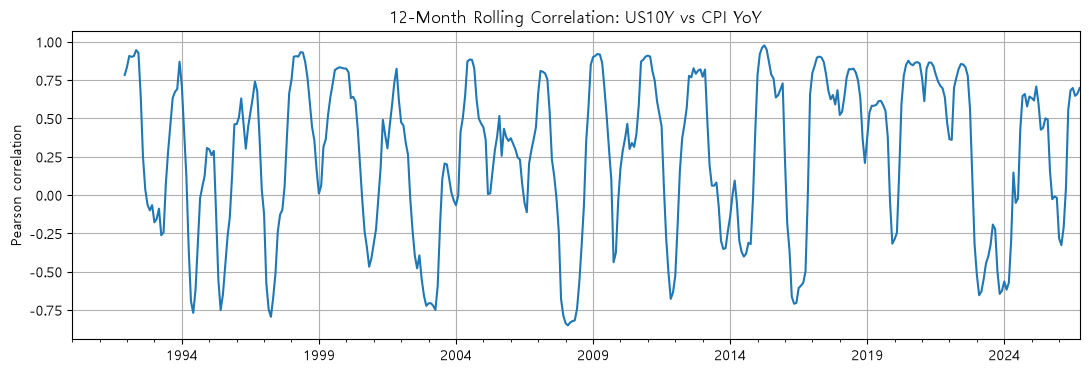

In [340]:
# 미국 10년물 국채금리(US10Y)와 소비자물가지수 상승률(CPI YoY) 사이의 12개월 이동 상관관계
# Rolling Correlation : 일정한 기간을 이동하면서 상관관계를 반복 계산 
monthly["Rolling_Corr_12M"].plot(
    title="12-Month Rolling Correlation: US10Y vs CPI YoY",
    ylabel="Pearson correlation",
    figsize=(13, 4)
)

In [341]:
''' 
## 결과 해석 ## 
* 1990년대 초반부터 2020년대 중반까지 미국 10년물 금리와 CPI 상승률의 12개월 롤링 상관계수 추이
* 상관계수가 +0.9 근처와 -0.8 근처 사이를 약 3~5년 주기로 크게 오르내림
* 상관계수가 0.20으로 낮은 이유 : 양의 상관 구간과 음의 상관 구간이 서로 상쇄되어 평균이 낮아짐
* 2024년 전후에도 음의 상관(약 -0.6)에서 양의 상관(약 +0.7)으로 급반전하는 모습
    * 배경 : 미국 대선 이후 감세, 관세, 재정확대에 따른 인플레이션 재점화 우려
            경기 연착륙 기대와 연준 인하 속도 조절 전망
            2025년 관세 정책 불확실성
'''

' \n## 결과 해석 ## \n* 1990년대 초반부터 2020년대 중반까지 미국 10년물 금리와 CPI 상승률의 12개월 롤링 상관계수 추이\n* 상관계수가 +0.9 근처와 -0.8 근처 사이를 약 3~5년 주기로 크게 오르내림\n* 상관계수가 0.20으로 낮은 이유 : 양의 상관 구간과 음의 상관 구간이 서로 상쇄되어 평균이 낮아짐\n* 2024년 전후에도 음의 상관(약 -0.6)에서 양의 상관(약 +0.7)으로 급반전하는 모습\n    * 배경 : 미국 대선 이후 감세, 관세, 재정확대에 따른 인플레이션 재점화 우려\n            경기 연착륙 기대와 연준 인하 속도 조절 전망\n            2025년 관세 정책 불확실성\n'

## 금리 및 물가 변화율
- US10Y_Change: 전월 대비 금리 변화폭(%p)
- US10Y_PctChange: 전월 대비 금리의 상대 변화율(%)
- US10Y_3M_Change: 3개월 전 대비 금리 변화폭(%p)
- CPI_YoY: CPI 전년 동월 대비 변화율(%)

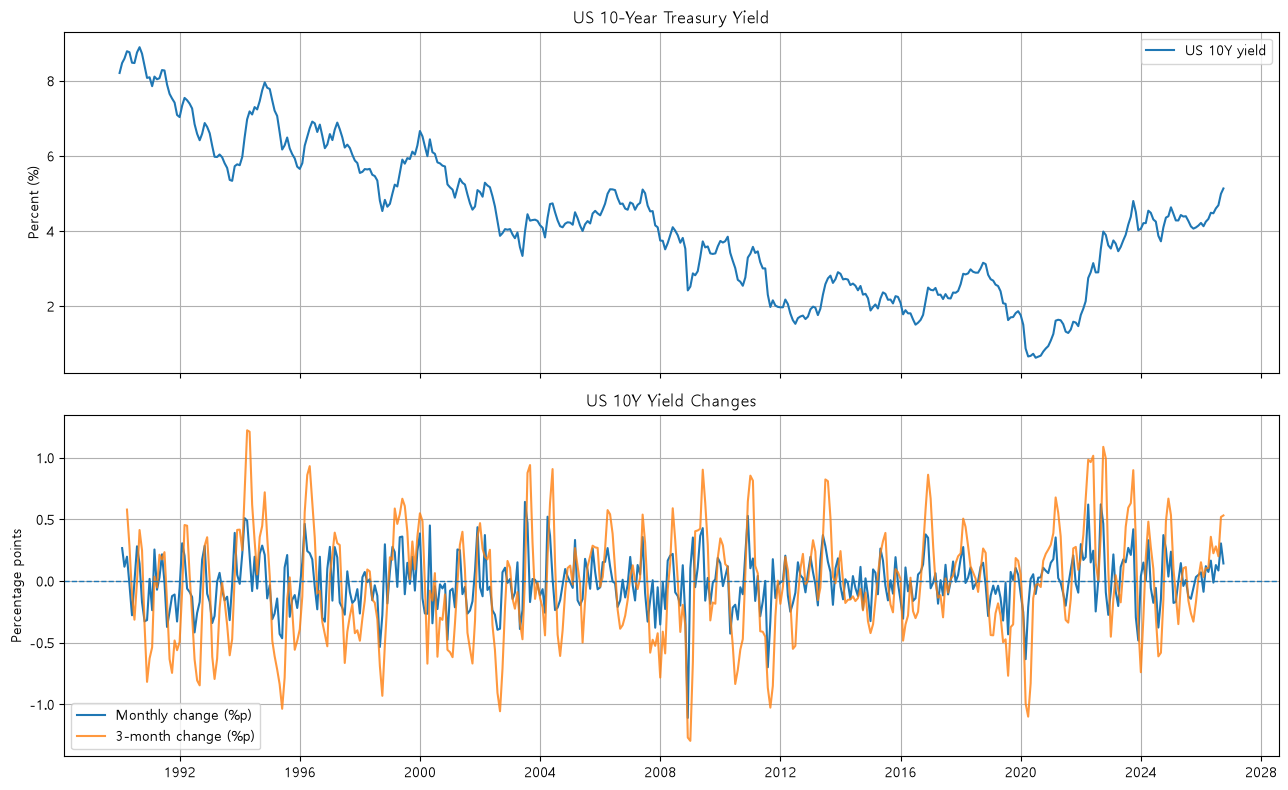

In [342]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

axes[0].plot(monthly.index, monthly["US10Y"], label="US 10Y yield")
axes[0].set_title("US 10-Year Treasury Yield")
axes[0].set_ylabel("Percent (%)")
axes[0].legend()

axes[1].plot(monthly.index, monthly["US10Y_Change"], label="Monthly change (%p)")
axes[1].plot(monthly.index, monthly["US10Y_3M_Change"], label="3-month change (%p)", alpha=0.8)
axes[1].axhline(0, linestyle="--", linewidth=1)
axes[1].set_title("US 10Y Yield Changes")
axes[1].set_ylabel("Percentage points")
axes[1].legend()

plt.tight_layout()
plt.show()

In [343]:
''' 
## 결과 해석 ##
= 10년물 금리
* 장기 추세: 1990년 이후 약 35년간의 하락 → 바닥 → 반등
* 1990년 초 약 8~9%에서 시작해 장기 하락 추세 
    - 인플레이션 안정(대안정기), 글로벌 저축 과잉, 금융위기 이후 양적완화 등이 복합적으로 작용
* 2020년 팬데믹 때 약 0.6%대로 사상 최저를 기록, 2022년부터 급등
* 2026년 후반에서는 약 5% 초반까지 상승, 2023년 고점(약 4.8~5%) 부근을 넘어서는 모습
* 2010년대의 초저금리 시대와는 완전히 다른 고금리 정상화 구간에 있음

= 10년물 국채금리 상승의 경제적 의미
* 1990년대 : 인플레이션 안정과 금리 하락
* 2000년대 : 글로벌 저축 증가와 저금리 기조
* 2008년 금융위기 : 경기침체와 안전자산 선호로 금리 하락
* 2020년 팬데믹 : 양적완화와 초저금리로 약 0.6% 기록
* 2022년 이후 : 인플레이션 급등과 연준의 금리 인상
* 2023년 이후 : 재정적자, 국채 공급, 장기 인플레이션 기대 등이 금리 상승 압력으로 작용

= 왜 10년물 국채금리가 상승
* 인플레이션 기대: 미래 물가가 상승할 것으로 예상하면 투자자는 더 높은 금리를 요구
* 실질금리: 물가상승률을 제외한 실질 수익률이 높아지면 명목 국채금리도 상승
* 기간 프리미엄(Term Premium): 장기간 자금을 묶어두는 위험에 대한 추가 보상

= 투자자 입장 : 10년물 금리가 상승하면 다음 현상이 나타날 수 있음
* 채권 가격 하락: 기존 저금리 채권의 매력 감소
* 주식시장 부담: 기업의 자금조달 비용과 미래 이익의 할인율 상승
* 달러 강세 가능성: 미국 자산의 상대적 수익률 상승
* 부동산시장 부담: 주택담보대출 금리 상승 압력

** 10년물 금리 상승 자체보다 경기 회복에 따른 상승, 인플레이션 우려, 재정적자와 국채 공급 증가에 따른 주식과 채권시장에 미치는 영향을 구분할 필요가 있음

'''

' \n## 결과 해석 ##\n= 10년물 금리\n* 장기 추세: 1990년 이후 약 35년간의 하락 → 바닥 → 반등\n* 1990년 초 약 8~9%에서 시작해 장기 하락 추세 \n    - 인플레이션 안정(대안정기), 글로벌 저축 과잉, 금융위기 이후 양적완화 등이 복합적으로 작용\n* 2020년 팬데믹 때 약 0.6%대로 사상 최저를 기록, 2022년부터 급등\n* 2026년 후반에서는 약 5% 초반까지 상승, 2023년 고점(약 4.8~5%) 부근을 넘어서는 모습\n* 2010년대의 초저금리 시대와는 완전히 다른 고금리 정상화 구간에 있음\n\n= 10년물 국채금리 상승의 경제적 의미\n* 1990년대 : 인플레이션 안정과 금리 하락\n* 2000년대 : 글로벌 저축 증가와 저금리 기조\n* 2008년 금융위기 : 경기침체와 안전자산 선호로 금리 하락\n* 2020년 팬데믹 : 양적완화와 초저금리로 약 0.6% 기록\n* 2022년 이후 : 인플레이션 급등과 연준의 금리 인상\n* 2023년 이후 : 재정적자, 국채 공급, 장기 인플레이션 기대 등이 금리 상승 압력으로 작용\n\n= 왜 10년물 국채금리가 상승\n* 인플레이션 기대: 미래 물가가 상승할 것으로 예상하면 투자자는 더 높은 금리를 요구\n* 실질금리: 물가상승률을 제외한 실질 수익률이 높아지면 명목 국채금리도 상승\n* 기간 프리미엄(Term Premium): 장기간 자금을 묶어두는 위험에 대한 추가 보상\n\n= 투자자 입장 : 10년물 금리가 상승하면 다음 현상이 나타날 수 있음\n* 채권 가격 하락: 기존 저금리 채권의 매력 감소\n* 주식시장 부담: 기업의 자금조달 비용과 미래 이익의 할인율 상승\n* 달러 강세 가능성: 미국 자산의 상대적 수익률 상승\n* 부동산시장 부담: 주택담보대출 금리 상승 압력\n\n** 10년물 금리 상승 자체보다 경기 회복에 따른 상승, 인플레이션 우려, 재정적자와 국채 공급 증가에 따른 주식과 채권시장에 미치는 영향을 구분할 필요가 있음\n\n'

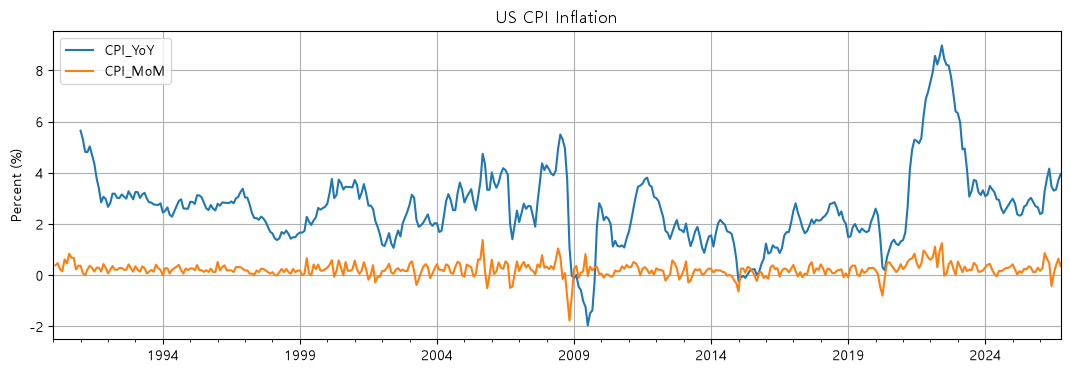

In [344]:
monthly[["CPI_YoY", "CPI_MoM"]].plot(
    title="US CPI Inflation",
    figsize=(13, 4),
    ylabel="Percent (%)"
)
plt.show()

In [345]:
''' 
## 결과 해석 ##
= CPI 인플레이션
* 1990년대~2000년대: YoY가 대체로 2~4% 범위에서 안정적
* 2008~2009년: 유가 급등 후 폭락으로 YoY가 5%대에서 **마이너스(약 -2%)**로 떨어짐 (디플레이션 우려)
* 2010년대: 0~3%의 저물가 구간이 이어짐
* 2021~2022년: 팬데믹 이후 공급망 차질과 재정·통화 부양으로 YoY가 약 9%까지 급등(40여 년 만의 최고 수준)
* 2023~2025년: 3% 안팎으로 내려왔지만 2% 목표에는 못 미쳤고, 그래프 우측 끝에서는 다시 4% 안팎으로 재상승
* MoM(주황)은 대부분 0~0.5% 사이인데, 최근 일부 구간에서 0.8% 가까이 튀는 값 보임
'''

' \n## 결과 해석 ##\n= CPI 인플레이션\n* 1990년대~2000년대: YoY가 대체로 2~4% 범위에서 안정적\n* 2008~2009년: 유가 급등 후 폭락으로 YoY가 5%대에서 **마이너스(약 -2%)**로 떨어짐 (디플레이션 우려)\n* 2010년대: 0~3%의 저물가 구간이 이어짐\n* 2021~2022년: 팬데믹 이후 공급망 차질과 재정·통화 부양으로 YoY가 약 9%까지 급등(40여 년 만의 최고 수준)\n* 2023~2025년: 3% 안팎으로 내려왔지만 2% 목표에는 못 미쳤고, 그래프 우측 끝에서는 다시 4% 안팎으로 재상승\n* MoM(주황)은 대부분 0~0.5% 사이인데, 최근 일부 구간에서 0.8% 가까이 튀는 값 보임\n'

In [346]:
''' 
= 두 지표를 합한 시사점
* 금리-물가 동행 : 2021~22년 CPI 급등 → 10년물 급등. 금리는 인플레이션을 후행·반영하는 경향이 뚜렷
* 현재 국면 : CPI가 4% 부근으로 재가속하면서 10년물이 5%대로 오르는 것은 
  인플레이션 재상승 우려 + 기간 프리미엄 확대를 시장이 반영하고 있음을 시사
* 실질금리 : 10년물 약 5% - CPI 약 4% ≈ 실질금리 +1%p 안팎. 2010년대(실질금리 0 또는 마이너스)보다 긴축적인 환경임
* 정책적인 딜레마 : 물가가 다시오르면 연준이 금리 인하를 하기 어려워짐. 장기금리가 더 오를 수 있음 
'''

' \n= 두 지표를 합한 시사점\n* 금리-물가 동행 : 2021~22년 CPI 급등 → 10년물 급등. 금리는 인플레이션을 후행·반영하는 경향이 뚜렷\n* 현재 국면 : CPI가 4% 부근으로 재가속하면서 10년물이 5%대로 오르는 것은 \n  인플레이션 재상승 우려 + 기간 프리미엄 확대를 시장이 반영하고 있음을 시사\n* 실질금리 : 10년물 약 5% - CPI 약 4% ≈ 실질금리 +1%p 안팎. 2010년대(실질금리 0 또는 마이너스)보다 긴축적인 환경임\n* 정책적인 딜레마 : 물가가 다시오르면 연준이 금리 인하를 하기 어려워짐. 장기금리가 더 오를 수 있음 \n'

## 장단기 금리차와 역전

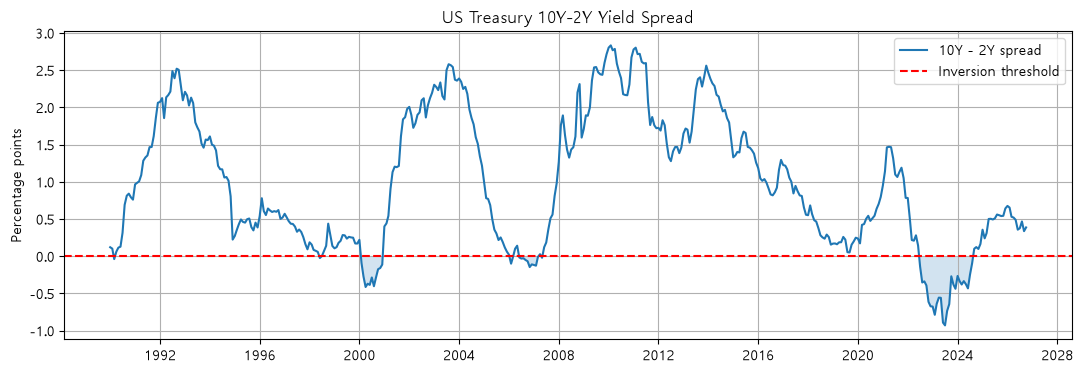

최근 장단기 금리차: 0.388 %p
최근 역전 여부: False


In [347]:
spread_data = monthly["Yield_Spread"].dropna()

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(spread_data.index, spread_data, label="10Y - 2Y spread")
ax.axhline(0, color="red", linestyle="--", label="Inversion threshold")
ax.fill_between(
    spread_data.index,
    spread_data,
    0,
    where=(spread_data < 0),
    alpha=0.2
)
ax.set_title("US Treasury 10Y-2Y Yield Spread")
ax.set_ylabel("Percentage points")
ax.legend()
plt.show()

print("최근 장단기 금리차:", round(spread_data.iloc[-1], 3), "%p")
print("최근 역전 여부:", bool(spread_data.iloc[-1] < 0))

In [348]:
''' 
## 결과해석 ##
= 미국 국채 10년-2년 금리 스프레드
* 10년물 금리에서 2년물 금리를 뺀 값(%p)의 추이(약 1990~2026년 말)
* 빨간 점선(0)보다 아래로 내려가면 장단기 금리 역전(단기금리가 장기금리보다 높은 상태), 역전 구간은 파란색으로 음영 처리되어 있음
* 스프레드 구간별 해석
- 2000~2001년 역전 (최저 약 -0.4%p) : 닷컴 버블 말기 긴축 후 역전이 나타났고, 이후 2001년 경기침체임
- 2006~2007년 역전 (최저 약 -0.1%p) : 역전 폭은 작지만 오래 지속되었고, 이후 2008년 글로벌 금융위기가 발생
- 2022~2024년 역전 (최저 약 -0.9%p) : 인플레이션에 대응한 급격한 금리 인상(연준의 긴축)으로 2년물 금리가 10년물을 크게 웃돔(2년간 지속)

= 시사점 
* 역전 해소 시점이 중요
- 스프레드가 다시 양(+)으로 돌아서는 시기(정상화)에 침체나 금리 인하가 본격화된 경우가 많음
- 이는 시장이 연준의 금리 인하를 선반영하며 단기금리가 먼저 떨어지기 때문임
'''

' \n## 결과해석 ##\n= 미국 국채 10년-2년 금리 스프레드\n* 10년물 금리에서 2년물 금리를 뺀 값(%p)의 추이(약 1990~2026년 말)\n* 빨간 점선(0)보다 아래로 내려가면 장단기 금리 역전(단기금리가 장기금리보다 높은 상태), 역전 구간은 파란색으로 음영 처리되어 있음\n* 스프레드 구간별 해석\n- 2000~2001년 역전 (최저 약 -0.4%p) : 닷컴 버블 말기 긴축 후 역전이 나타났고, 이후 2001년 경기침체임\n- 2006~2007년 역전 (최저 약 -0.1%p) : 역전 폭은 작지만 오래 지속되었고, 이후 2008년 글로벌 금융위기가 발생\n- 2022~2024년 역전 (최저 약 -0.9%p) : 인플레이션에 대응한 급격한 금리 인상(연준의 긴축)으로 2년물 금리가 10년물을 크게 웃돔(2년간 지속)\n\n= 시사점 \n* 역전 해소 시점이 중요\n- 스프레드가 다시 양(+)으로 돌아서는 시기(정상화)에 침체나 금리 인하가 본격화된 경우가 많음\n- 이는 시장이 연준의 금리 인하를 선반영하며 단기금리가 먼저 떨어지기 때문임\n'

## Sahm Rule 및 NBER 경기침체 지표

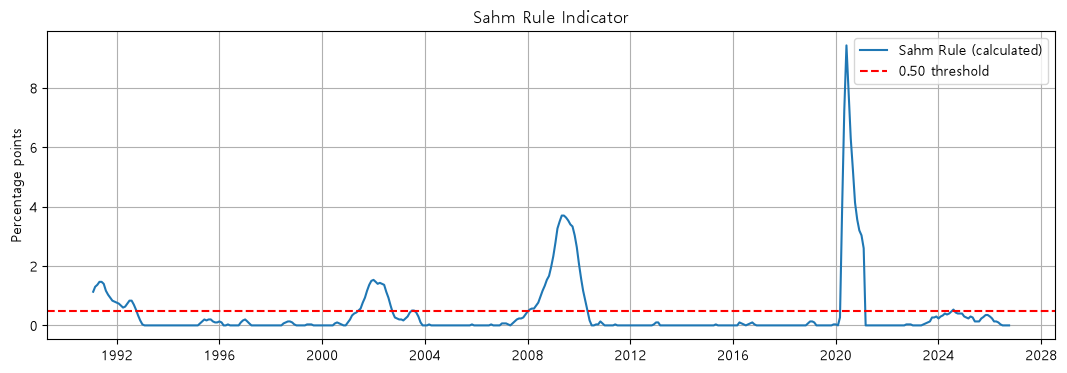

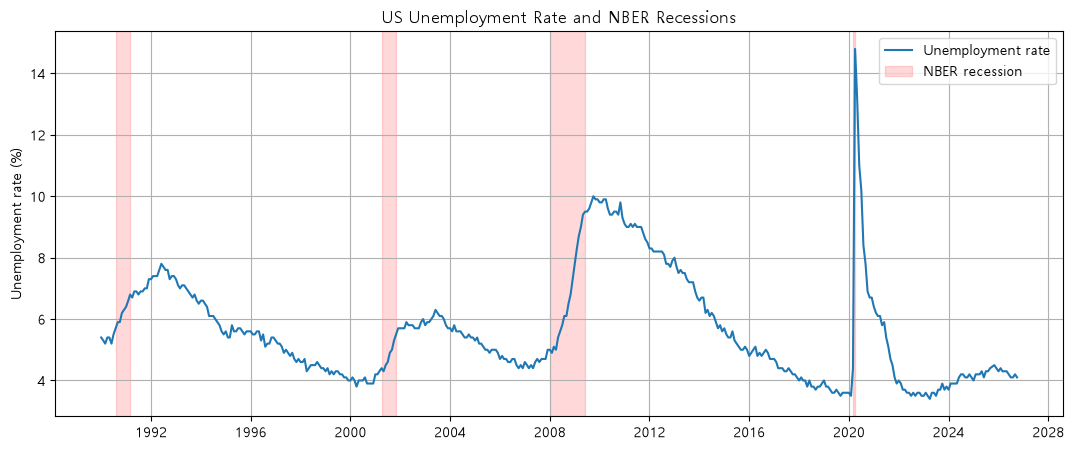

최근 관측 월: 2026-10
10년물 금리: 5.13%
CPI YoY: 3.95%
실업률: 4.10%
10Y-2Y 금리차: 0.39%p
Sahm Rule: 0.00%p
NBER 침체 표시: 0


In [349]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(monthly.index, monthly["Sahm_Rule"], label="Sahm Rule (calculated)")
ax.axhline(0.50, color="red", linestyle="--", label="0.50 threshold")
ax.set_title("Sahm Rule Indicator")
ax.set_ylabel("Percentage points")
ax.legend()
plt.show()

# 실업률과 NBER 경기침체 기간
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(monthly.index, monthly["UNRATE"], label="Unemployment rate")
recession = monthly["USREC"].fillna(0).astype(float) == 1
ax.fill_between(
    monthly.index, 0, 1,
    where=recession,
    transform=ax.get_xaxis_transform(),
    alpha=0.15,
    color="red",
    label="NBER recession"
)
ax.set_title("US Unemployment Rate and NBER Recessions")
ax.set_ylabel("Unemployment rate (%)")
ax.legend()
plt.show()

latest = monthly.dropna(subset=["US10Y", "CPI_YoY", "UNRATE", "T10Y2Y"]).iloc[-1]
print("최근 관측 월:", latest.name.strftime("%Y-%m"))
print(f"10년물 금리: {latest['US10Y']:.2f}%")
print(f"CPI YoY: {latest['CPI_YoY']:.2f}%")
print(f"실업률: {latest['UNRATE']:.2f}%")
print(f"10Y-2Y 금리차: {latest['T10Y2Y']:.2f}%p")
print(f"Sahm Rule: {latest['Sahm_Rule']:.2f}%p")
print(f"NBER 침체 표시: {int(latest['USREC'])}")

In [350]:
''' 
## 결과해석 ##
= 삼 룰(Sahm Rule) 지표(상단 그래프)
* 삼 룰은 최근 3개월 평균 실업률이 직전 12개월 중 최저치보다 0.5%p 이상 높아지면 경기침체 초입으로 보는 규칙, 빨간 점선(0.50)이 기준선
* 그래프 해석
- 1991년: 약 1.4까지 올라 침체 신호가 나타남 
- 2001~2002년: 약 1.5까지 올라 신호가 발생
- 2008~2009년: 3.7 안팎까지 올랐습니다. 금융위기 때의 급격한 고용 악화가 반영
- 2020년: 코로나 충격으로 9.5 가까이 치솟았고, 이후 빠르게 0으로 떨어짐
- 2024년 중반: 0.5 부근까지 올라 기준선을 살짝 넘음
- 2025~2026년: 다시 0에 가까워졌고, 지금은 신호가 꺼진 상태
'''

' \n## 결과해석 ##\n= 삼 룰(Sahm Rule) 지표(상단 그래프)\n* 삼 룰은 최근 3개월 평균 실업률이 직전 12개월 중 최저치보다 0.5%p 이상 높아지면 경기침체 초입으로 보는 규칙, 빨간 점선(0.50)이 기준선\n* 그래프 해석\n- 1991년: 약 1.4까지 올라 침체 신호가 나타남 \n- 2001~2002년: 약 1.5까지 올라 신호가 발생\n- 2008~2009년: 3.7 안팎까지 올랐습니다. 금융위기 때의 급격한 고용 악화가 반영\n- 2020년: 코로나 충격으로 9.5 가까이 치솟았고, 이후 빠르게 0으로 떨어짐\n- 2024년 중반: 0.5 부근까지 올라 기준선을 살짝 넘음\n- 2025~2026년: 다시 0에 가까워졌고, 지금은 신호가 꺼진 상태\n'

In [351]:
''' 
## 결과해석 ##
= 실업률과 NBER 침체 구간(하단 그래프)
* 분홍색 음영은 NBER이 공식 지정한 침체 기간
* 실업률은 침체 구간에서 급등하고, 침체가 끝난 뒤에도 한동안 높은 수준을 유지하는 경향
* 그래프 해석
- 1990~91년, 2001년, 2007~09년, 2020년 침체 때 모두 실업률이 뚜렷하게 상승
- 2009~2010년에는 10%까지 올랐고, 2020년 4월에는 약 14.8%로 역대급 급등
- 현재(2026년)는 4% 초중반 수준으로 비교적 안정적
'''

' \n## 결과해석 ##\n= 실업률과 NBER 침체 구간(하단 그래프)\n* 분홍색 음영은 NBER이 공식 지정한 침체 기간\n* 실업률은 침체 구간에서 급등하고, 침체가 끝난 뒤에도 한동안 높은 수준을 유지하는 경향\n* 그래프 해석\n- 1990~91년, 2001년, 2007~09년, 2020년 침체 때 모두 실업률이 뚜렷하게 상승\n- 2009~2010년에는 10%까지 올랐고, 2020년 4월에는 약 14.8%로 역대급 급등\n- 현재(2026년)는 4% 초중반 수준으로 비교적 안정적\n'

In [352]:
''' 
## 결과해석(두 지표 같이 보기) ##
* 삼 룰이 0.5를 넘은 시점은 대부분 NBER 침체 구간 직전이거나 초기
* NBER 공식 발표는 보통 침체가 시작된 지 한참 뒤에 나옴 
* 삼 룰은 실시간 조기 경보로서 가치가 있음
* 2024년 중반에는 지표가 삼룰이 0.5 부근까지 올랐지만 NBER 침체 음영이 없었음 : 신호가 침체로 이어지지 않음 
- 해고 증가보다 노동 공급 증가(이민 유입, 구직자 복귀) 때문에 실업률이 올랐다는 해석
* 삼 룰은 실업률 하나만 보는 지표임 : 신규 실업수당 청구, 비농업 고용, 수익률 곡선 등 다른 지표와 함께 보는 것이 타당

'''

' \n## 결과해석(두 지표 같이 보기) ##\n* 삼 룰이 0.5를 넘은 시점은 대부분 NBER 침체 구간 직전이거나 초기\n* NBER 공식 발표는 보통 침체가 시작된 지 한참 뒤에 나옴 \n* 삼 룰은 실시간 조기 경보로서 가치가 있음\n* 2024년 중반에는 지표가 삼룰이 0.5 부근까지 올랐지만 NBER 침체 음영이 없었음 : 신호가 침체로 이어지지 않음 \n- 해고 증가보다 노동 공급 증가(이민 유입, 구직자 복귀) 때문에 실업률이 올랐다는 해석\n* 삼 룰은 실업률 하나만 보는 지표임 : 신규 실업수당 청구, 비농업 고용, 수익률 곡선 등 다른 지표와 함께 보는 것이 타당\n\n'

## 머신러닝: 향후 6개월 경기침체 분류

In [353]:
FEATURES = [
    "US10Y",
    "US10Y_Change",
    "CPI_YoY",
    "FEDFUNDS",
    "T10Y2Y",
    "UNRATE",
    "Sahm_Rule",
    "PAYEMS_Change",
]

# 한 달 전까지 관측된 값을 현재 예측 시점의 입력으로 사용
X_all = monthly[FEATURES].shift(1)

# 다음 1~6개월 중 NBER 침체가 한 번이라도 있으면 1
future_recession = pd.concat(
    [monthly["USREC"].shift(-h) for h in range(1, 7)],
    axis=1
).max(axis=1)

dataset = X_all.copy()
dataset["Target"] = future_recession
dataset = dataset.dropna(subset=["Target"])

# 입력 결측치는 Pipeline의 SimpleImputer에서 처리
dataset = dataset.dropna(subset=["US10Y", "CPI_YoY", "T10Y2Y"])

X = dataset[FEATURES]
y = dataset["Target"].astype(int)

print("학습 데이터 크기:", X.shape)
print("타깃 분포:")
display(y.value_counts().rename(index={0: "No recession in next 6 months", 1: "Recession within next 6 months"}))

if y.nunique() < 2:
    raise ValueError("타깃에 클래스가 하나만 있습니다. 데이터 기간과 타깃 정의를 확인하세요.")

# 시간 순서 유지: 앞 80% 학습, 뒤 20% 테스트
split_idx = int(len(dataset) * 0.80)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print("Train:", X_train.index.min(), "~", X_train.index.max())
print("Test :", X_test.index.min(), "~", X_test.index.max())
print("Train target counts:", y_train.value_counts().to_dict())
print("Test target counts:", y_test.value_counts().to_dict())

학습 데이터 크기: (428, 8)
타깃 분포:


Target
No recession in next 6 months     384
Recession within next 6 months     44
Name: count, dtype: int64

Train: 1991-02-01 00:00:00 ~ 2019-07-01 00:00:00
Test : 2019-08-01 00:00:00 ~ 2026-09-01 00:00:00
Train target counts: {0: 305, 1: 37}
Test target counts: {0: 79, 1: 7}


## 모델 학습 및 평가

In [354]:
# 데이터 누수(data leakage) : 모델을 평가할 때, 검증 데이터의 정보가 학습 과정에 몰래 들어가는 것을 말함.
                            # 그러면 성능이 실제보다 좋게 나와서 평가가 왜곡됨
models = {
    "Logistic Regression": Pipeline([
        # SimpleImputer 파라메터 : add_indicator=True - 결측이었던 열에 대해 이진 플래그가 추가
        # 결측 자체가 의미 있는 정보라면 성능에 도움이 되고, 특히 로지스틱 회귀에서 효과적
        ("imputer", SimpleImputer(strategy="median")),   # 결측치가 있다면 중앙값으로 대체 
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",                     # 클래스의 불균형을  보정하기 위함 
            max_iter=2000,
            random_state=RANDOM_STATE
        ))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=4,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ])
}


In [355]:
# 1.초기화
    # 학습이 끝난 모델 객체를 보관할 딕셔너리와, 모델별 성능 지표를 쌓을 리스트
fitted_models = {}
results = []

# 2.모델 학습 및 예측
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted_models[name] = model

    pred = model.predict(X_test)              # 예측 클래스 레이블(0 또는 1)
    prob = model.predict_proba(X_test)[:, 1]  # 양성 클래스(1)에 속할 확률

    # 상세 성능 출력 
    print(f"\n===== {name} =====")
    # 클래스별 precision, recall, f1-score, support
    # zero_division=0 : 분모가 0인 지표를 0으로 처리하고 경고를 억제
    print(classification_report(y_test, pred, zero_division=0))
    print("Confusion matrix:")
    print(confusion_matrix(y_test, pred))

    # 확률 기반 지표 계산
        # ROC AUC: 임계값을 바꿔가며 TPR과 FPR의 관계를 본 곡선의 면적
            # 모델이 음성, 양성인지를 얼마나 잘 구분하는지를 나타냄
        # PR AUC (Average Precision) : precision-recall 곡선의 요약값
            # 클래스 불균형이 심할 때 ROC AUC보다 더 민감하게 성능 차이를 보여줌
        # y_test.nunique() == 2 : 조건은 테스트 세트에 두 클래스가 모두 있을 때만 계산을 하는 안전장치
        # else np.nan : 클래스가 하나만 있으며 AUC를 정의할 수 없어서 에러가 남, NaN을 Default값으로 넣음
    roc = roc_auc_score(y_test, prob) if y_test.nunique() == 2 else np.nan
    pr = average_precision_score(y_test, prob) if y_test.nunique() == 2 else np.nan

    results.append({
        "Model": name,
        "ROC_AUC": roc,
        "PR_AUC": pr
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(3))


===== Logistic Regression =====


              precision    recall  f1-score   support

           0       0.82      0.35      0.50        79
           1       0.02      0.14      0.03         7

    accuracy                           0.34        86
   macro avg       0.42      0.25      0.26        86
weighted avg       0.76      0.34      0.46        86

Confusion matrix:
[[28 51]
 [ 6  1]]

===== Random Forest =====
              precision    recall  f1-score   support

           0       0.88      0.62      0.73        79
           1       0.00      0.00      0.00         7

    accuracy                           0.57        86
   macro avg       0.44      0.31      0.36        86
weighted avg       0.80      0.57      0.67        86

Confusion matrix:
[[49 30]
 [ 7  0]]


,ROC_AUC,PR_AUC
Model,,
Logistic Regression,0.304,0.066
Random Forest,0.014,0.048


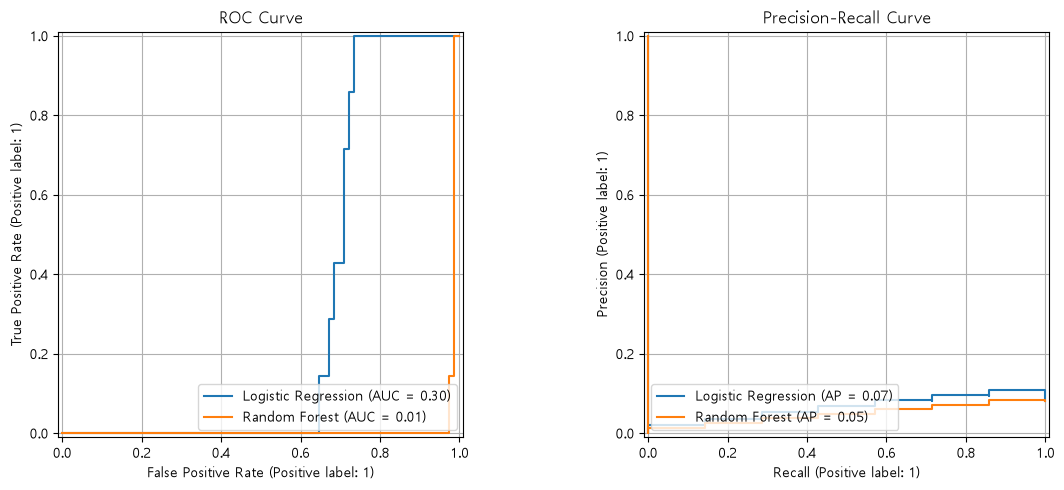

In [356]:
# 모델별 ROC 및 Precision-Recall 곡선
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for name, model in fitted_models.items():
    prob = model.predict_proba(X_test)[:, 1]
    if y_test.nunique() == 2:
        RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=axes[0])
        PrecisionRecallDisplay.from_predictions(y_test, prob, name=name, ax=axes[1])

axes[0].set_title("ROC Curve")
axes[1].set_title("Precision-Recall Curve")
plt.tight_layout()
plt.show()

In [357]:
'''
* Logistic Regression
    * FPR이 약 0.65에 도달할 때까지 TPR이 거의 0입니다. 음성 샘플의 65%가 양성 7건보다 먼저 높은 점수를 받았음
    * FPR 0.65~0.73 구간에서 TPR이 급격히 올라 1.0에 도달
    * 양성 샘플이 점수 순위 하위권
* Random Forest
    * FPR 약 0.97까지 TPR이 0에 붙어 있다가 맨 오른쪽에서 한꺼번에 1.0으로 올라감
    * 곡선이 ㄴ자 모양으로 우하단에 붙은 형태는 사실상 완벽하게 반대로 예측한 전형적인 패턴
'''

'\n* Logistic Regression\n    * FPR이 약 0.65에 도달할 때까지 TPR이 거의 0입니다. 음성 샘플의 65%가 양성 7건보다 먼저 높은 점수를 받았음\n    * FPR 0.65~0.73 구간에서 TPR이 급격히 올라 1.0에 도달\n    * 양성 샘플이 점수 순위 하위권\n* Random Forest\n    * FPR 약 0.97까지 TPR이 0에 붙어 있다가 맨 오른쪽에서 한꺼번에 1.0으로 올라감\n    * 곡선이 ㄴ자 모양으로 우하단에 붙은 형태는 사실상 완벽하게 반대로 예측한 전형적인 패턴\n'

## 최근 시점의 모델 예측

In [358]:
best_model_name = results_df["PR_AUC"].idxmax()
best_model = fitted_models[best_model_name]

latest_X = X.iloc[[-1]]
latest_probability = best_model.predict_proba(latest_X)[0, 1]

print("선택 모델:", best_model_name)
print("예측 기준월:", latest_X.index[-1].strftime("%Y-%m"))
print(f"향후 6개월 경기침체 분류 점수: {latest_probability:.1%}")
print("주의: 이 값은 검증된 실시간 경기침체 확률이 아닌 모델 출력 점수입니다.")

선택 모델: Logistic Regression
예측 기준월: 2026-09
향후 6개월 경기침체 분류 점수: 19.4%
주의: 이 값은 검증된 실시간 경기침체 확률이 아닌 모델 출력 점수입니다.


## 변수 중요도

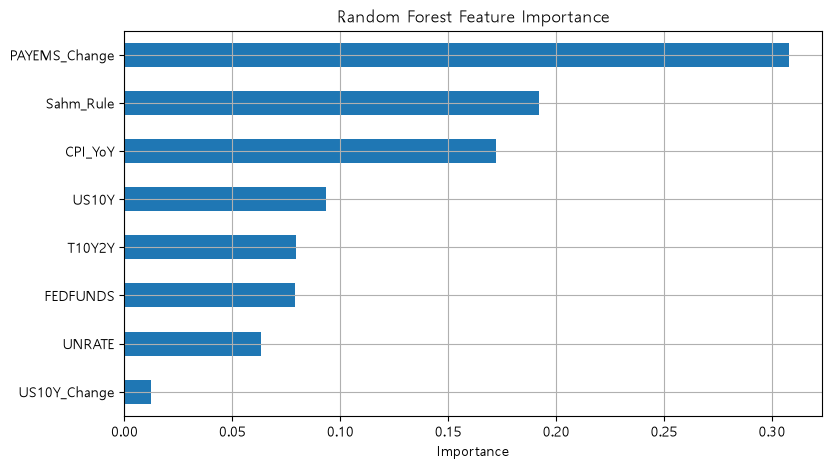

,Importance
PAYEMS_Change,0.307796
Sahm_Rule,0.192320
CPI_YoY,0.172109
US10Y,0.093279
T10Y2Y,0.079652
FEDFUNDS,0.079172
UNRATE,0.063167
US10Y_Change,0.012506


In [359]:
rf = fitted_models["Random Forest"].named_steps["model"]
importance = pd.Series(
    rf.feature_importances_,
    index=FEATURES
).sort_values(ascending=True)

importance.plot(
    kind="barh",
    title="Random Forest Feature Importance",
    figsize=(9, 5)
)
plt.xlabel("Importance")
plt.show()

display(importance.sort_values(ascending=False).to_frame("Importance"))

## 결과 저장

In [360]:
monthly.to_csv(OUTPUT_DIR / "us_macro_monthly.csv", encoding="utf-8-sig")
corr_matrix.to_csv(OUTPUT_DIR / "correlation_matrix.csv", encoding="utf-8-sig")
results_df.to_csv(OUTPUT_DIR / "model_evaluation.csv", encoding="utf-8-sig")
importance.sort_values(ascending=False).to_csv(
    OUTPUT_DIR / "feature_importance.csv",
    header=["importance"],
    encoding="utf-8-sig"
)

print("저장 완료:")
for path in sorted(OUTPUT_DIR.glob("*.csv")):
    print("-", path)

저장 완료:
- outputs\correlation_matrix.csv
- outputs\feature_importance.csv
- outputs\model_evaluation.csv
- outputs\us_macro_monthly.csv


* test code - start

In [361]:
import pandas as pd
import numpy as np

s = pd.Series([np.nan, 100, np.nan, 120, np.nan])

print(s)

0      NaN
1    100.0
2      NaN
3    120.0
4      NaN
dtype: float64


In [362]:
s.ffill()

0      NaN
1    100.0
2    100.0
3    120.0
4    120.0
dtype: float64

In [363]:
s.ffill().notna()

0    False
1     True
2     True
3     True
4     True
dtype: bool

In [364]:
import pandas as pd

s = pd.Series([10, 20, 30, 40, 50])
result = s.where(s >= 30, 0)

print(result)

0     0
1     0
2    30
3    40
4    50
dtype: int64


In [365]:
import pandas as pd
import numpy as np

dates = pd.date_range("2024-01-01", periods=8, freq="MS")

s = pd.Series(
    [100, np.nan, 120, np.nan, np.nan, 150, 160, np.nan],
    index=dates,
    name="US10Y"
)

print(s)

2024-01-01    100.0
2024-02-01      NaN
2024-03-01    120.0
2024-04-01      NaN
2024-05-01      NaN
2024-06-01    150.0
2024-07-01    160.0
2024-08-01      NaN
Freq: MS, Name: US10Y, dtype: float64


In [366]:
result = fill_short_gaps(
    s,
    method="time",
    max_gap=1
)

display(pd.DataFrame({
    "원본": s,
    "보간 결과": result
}))

,원본,보간 결과
2024-01-01,100.0,100.000000
2024-02-01,NaN,110.333333
2024-03-01,120.0,120.000000
2024-04-01,NaN,NaN
2024-05-01,NaN,NaN
2024-06-01,150.0,150.000000
2024-07-01,160.0,160.000000
2024-08-01,NaN,NaN


In [367]:
result_1 = fill_short_gaps(s, method="time", max_gap=1)
result_2 = fill_short_gaps(s, method="time", max_gap=2)

display(pd.DataFrame({
    "원본": s,
    "max_gap=1": result_1,
    "max_gap=2": result_2
}))

,원본,max_gap=1,max_gap=2
2024-01-01,100.0,100.000000,100.000000
2024-02-01,NaN,110.333333,110.333333
2024-03-01,120.0,120.000000,120.000000
2024-04-01,NaN,NaN,130.108696
2024-05-01,NaN,NaN,139.891304
2024-06-01,150.0,150.000000,150.000000
2024-07-01,160.0,160.000000,160.000000
2024-08-01,NaN,NaN,NaN


In [368]:
import pandas as pd
import numpy as np

# 테스트 데이터
s = pd.Series([100, np.nan, 104, np.nan, np.nan, 110])

# 결측 여부 확인
isna = s.isna()

# 결측 구간별 길이 계산
run_len = isna.groupby((~isna).cumsum()).transform("sum")

# 결과 출력
result = pd.DataFrame({
    "원본값": s,
    "결측여부": isna,
    "그룹번호": (~isna).cumsum(),
    "연속결측길이": run_len
})

print(result)

     원본값   결측여부  그룹번호  연속결측길이
0  100.0  False     1       1
1    NaN   True     1       1
2  104.0  False     2       2
3    NaN   True     2       2
4    NaN   True     2       2
5  110.0  False     3       0


In [369]:
this_month = pd.Timestamp.today().to_period("M").to_timestamp()
partial = monthly.index[monthly.index >= this_month]
partial

DatetimeIndex([], dtype='datetime64[ns]', freq='MS')

In [370]:
import pandas as pd

# 월초가 아닌 날짜를 일부러 포함
monthly = pd.DataFrame(
    {
        "US10Y": [3.5, 3.6, 3.7, 3.8, 3.9, 4.0],
        "CPI": [300.1, 301.2, 302.3, 303.4, 304.5, 305.6]
    },
    index=pd.to_datetime([
        "2024-01-01",  # 정상
        "2024-02-01",  # 정상
        "2024-03-15",  # 비정상
        "2024-04-01",  # 정상
        "2024-05-20",  # 비정상
        "2024-06-01"   # 정상
    ])
)

monthly.index.name = "Date"

display(monthly)

full_idx = pd.date_range(
    monthly.index.min(),
    monthly.index.max(),
    freq="MS",
    name=monthly.index.name
)

display(full_idx)

off_grid = monthly.index.difference(full_idx)

print("월초가 아닌 날짜:", list(off_grid))

,US10Y,CPI
Date,,
2024-01-01,3.5,300.1
2024-02-01,3.6,301.2
2024-03-15,3.7,302.3
2024-04-01,3.8,303.4
2024-05-20,3.9,304.5
2024-06-01,4.0,305.6


DatetimeIndex(['2024-01-01', '2024-02-01', '2024-03-01', '2024-04-01', '2024-05-01', '2024-06-01'], dtype='datetime64[ns]', name='Date', freq='MS')

월초가 아닌 날짜: [Timestamp('2024-03-15 00:00:00'), Timestamp('2024-05-20 00:00:00')]


In [371]:
import pandas as pd

monthly = pd.DataFrame(
    {"CPI": [300, 302, 305, 308]},
    index=pd.to_datetime([
        "2024-01-01",
        "2024-02-01",
        "2024-04-01",
        "2024-06-01"
    ])
)

monthly.index.name = "Date"

display(monthly)

full_idx = pd.date_range(
    monthly.index.min(),
    monthly.index.max(),
    freq="MS",
    name=monthly.index.name
)

missing_rows = full_idx.difference(monthly.index)

print(f"행 수: {len(monthly)}개")
print(f"누락된 월: {[d.strftime('%Y-%m') for d in missing_rows] or '없음'}")

if len(missing_rows):
    monthly = monthly.reindex(full_idx)

display(monthly)

,CPI
Date,
2024-01-01,300
2024-02-01,302
2024-04-01,305
2024-06-01,308


행 수: 4개
누락된 월: ['2024-03', '2024-05']


,CPI
Date,
2024-01-01,300.0
2024-02-01,302.0
2024-03-01,NaN
2024-04-01,305.0
2024-05-01,NaN
2024-06-01,308.0


* test ccode - stop